# Data Science Tool Mastery: Retail Analytics Portfolio

**Dataset:** UCI Online Retail, real historical transactions, CC BY 4.0. Analysis is observational; business descriptions are not causal claims. Source: https://archive.ics.uci.edu/dataset/352/online+retail

## Dataset and business case
This data records transaction line items for a UK non-store retailer, 1 Dec 2010–9 Dec 2011. Source metadata lists 541,909 instances and eight columns: InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country. Questions: sales concentration, customer repeat behavior, product mix, and whether a basic time-series regression beats a simple weekly-naive baseline.

In [1]:
from pathlib import Path
import json, runpy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import TimeSeriesSplit
ROOT=Path.cwd()
if not (ROOT/"datasets").exists(): ROOT=ROOT.parent
print("Root:",ROOT)

Root: /home/user/Data-Science-Tool-Mastery


## 1. Python Fundamentals
Demonstrate typed variables, conditionals, loops, functions, collection types, exceptions, and file handling.

In [2]:
# Variables and data types
project="Retail analytics"; revenue=125.50; is_valid=True
print(type(project).__name__, type(revenue).__name__, type(is_valid).__name__)
# if, loop, function
status="high" if revenue>=100 else "low"
for x in [1,2,3]: print(x, end=" ")
def safe_average(values):
    try: return sum(values)/len(values)
    except ZeroDivisionError: return None
print("\nstatus",status,"avg",safe_average([1,2,3]),"empty",safe_average([]))
# list, tuple, dict, set
items=["tea","gift"]; point=(1,2); kpi={"revenue":revenue}; unique=set(items+items)
print(items,point,kpi,unique)
# exception and file IO
try: int("not-a-number")
except ValueError as exc: print("Handled:",type(exc).__name__)
tmp=ROOT/"module1_example.txt"; tmp.write_text("portfolio file I/O demo")
print(tmp.read_text()); tmp.unlink()

str float bool
1 2 3 
status high avg 2.0 empty None
['tea', 'gift'] (1, 2) {'revenue': 125.5} {'tea', 'gift'}
Handled: ValueError
portfolio file I/O demo


## 2. NumPy
Array creation, indexing, vectorization, aggregation, missing-value handling and matrix multiplication.

In [3]:
a=np.array([[1.,2.,np.nan],[4.,5.,6.]])
print("shape",a.shape,"slice",a[:,1:])
print("mean by col ignoring NaN",np.nanmean(a,axis=0))
filled=np.where(np.isnan(a),np.nanmean(a,axis=0),a)
print("vector x 2",filled*2,"sum",np.sum(filled))
print("matrix product",np.array([[1,2],[3,4]])@np.array([[2],[1]]).ravel())

shape (2, 3) slice [[ 2. nan]
 [ 5.  6.]]
mean by col ignoring NaN [2.5 3.5 6. ]
vector x 2 [[ 2.  4. 12.]
 [ 8. 10. 12.]] sum 24.0
matrix product [ 4 10]


## 3. Pandas
Read the cleaned transaction-line CSV, inspect, filter/sort/group, merge, and export. Dataset load and cleaning trace are reproducible with `python src/run_analysis.py`.

In [4]:
clean=pd.read_csv(ROOT/"datasets/processed/online_retail_clean.csv",parse_dates=["InvoiceDate"])
print(clean.shape); display(clean.head()); display(clean.dtypes); display(clean.describe(include="all").T.head(10))
valid=clean.query("IsCancellation == False and Quantity > 0 and UnitPrice > 0").copy()
print(valid.sort_values("LineRevenue",ascending=False)[["InvoiceNo","Country","LineRevenue"]].head())
country_kpi=valid.groupby("Country",as_index=False).agg(revenue=("LineRevenue","sum"),orders=("InvoiceNo","nunique"))
display(country_kpi.sort_values("revenue",ascending=False).head())
# Join grouped customer KPIs to a small country dimension as a merge demonstration
dim=country_kpi[["Country"]].drop_duplicates(); joined=country_kpi.merge(dim,on="Country",validate="one_to_one")
print("merged rows",len(joined),"missing IDs retained as unknown",clean.CustomerID.isna().sum())

(536641, 11)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,LineRevenue,Date
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,False,15.30,2010-12-01
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,False,22.00,2010-12-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,False,20.34,2010-12-01


InvoiceNo                 object
StockCode                 object
Description               object
Quantity                   int64
InvoiceDate       datetime64[ns]
UnitPrice                float64
CustomerID               float64
Country                   object
IsCancellation              bool
LineRevenue              float64
Date                      object
dtype: object

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,536641,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,536641,3958,85123A,2368,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,536641,4195,WHITE HANGING HEART T-LIGHT HOLDER,2357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,536641.0,NaN,NaN,NaN,9.620029,-80995.0,1.0,3.0,10.0,80995.0,219.130156
InvoiceDate,536641,NaN,NaN,NaN,2011-07-04 08:57:06.087421952,2010-12-01 08:26:00,2011-03-28 10:52:00,2011-07-19 14:04:00,2011-10-18 17:05:00,2011-12-09 12:50:00,NaN
UnitPrice,536641.0,NaN,NaN,NaN,4.632656,-11062.06,1.25,2.08,4.13,38970.0,97.233118
CustomerID,401604.0,NaN,NaN,NaN,15281.160818,12346.0,13939.0,15145.0,16784.0,18287.0,1714.006089
Country,536641,38,United Kingdom,490300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IsCancellation,536641,2,False,527390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LineRevenue,536641.0,NaN,NaN,NaN,18.123861,-168469.6,3.75,9.87,17.4,168469.6,380.656263


       InvoiceNo         Country  LineRevenue
535160    581483  United Kingdom    168469.60
61006     541431  United Kingdom     77183.60
220825    556444  United Kingdom     38970.00
14757     537632  United Kingdom     13541.33
297645   A563185  United Kingdom     11062.06


,Country,revenue,orders
35,United Kingdom,9001744.094,18019
24,Netherlands,285446.340,94
10,Eire,283140.520,288
14,Germany,228678.400,457
13,France,209625.370,392


merged rows 38 missing IDs retained as unknown 135037


## 4. SQL and Database Management
MySQL 8 schema, indexes, 24 analytical queries (CTEs, subqueries, CASE, joins/window functions, views) are in `04_SQL/`. Import the processed CSV with MySQL Workbench. A MySQL server/Workbench was not available in this execution environment; SQL files are MySQL-targeted and local database execution is an evaluator setup step.

In [5]:
print((ROOT/"04_SQL/02_analytical_queries_mysql.sql").read_text()[:2200])

USE retail_analytics;
-- 01: Basic data sample
SELECT * FROM retail_transactions LIMIT 20;
-- 02: Revenue by month
SELECT DATE_FORMAT(InvoiceDate,'%Y-%m') AS month, SUM(LineRevenue) AS gross_sales FROM retail_transactions WHERE IsCancellation=0 AND Quantity>0 AND UnitPrice>0 GROUP BY month ORDER BY month;
-- 03: Revenue by country
SELECT Country,SUM(LineRevenue) sales FROM retail_transactions WHERE IsCancellation=0 AND Quantity>0 AND UnitPrice>0 GROUP BY Country ORDER BY sales DESC;
-- 04: Order count per country
SELECT Country,COUNT(DISTINCT InvoiceNo) orders FROM retail_transactions WHERE IsCancellation=0 GROUP BY Country ORDER BY orders DESC;
-- 05: Top 20 products
SELECT StockCode,MAX(Description) product,SUM(Quantity) units,SUM(LineRevenue) revenue FROM retail_transactions WHERE IsCancellation=0 AND Quantity>0 AND UnitPrice>0 GROUP BY StockCode ORDER BY revenue DESC LIMIT 20;
-- 06: Average invoice value
SELECT AVG(invoice_total) avg_order_value FROM (SELECT InvoiceNo,SUM(LineReve

## 5. Data Cleaning and Preprocessing
Exact duplicate rows are removed. IDs retain string semantics, dates parse as timestamps, descriptions/countries are trimmed and cased, missing descriptions become `UNKNOWN PRODUCT`. CustomerID remains null because customer identity cannot be safely inferred; transaction-level country and revenue analysis retains those rows. Cancellation/return rows stay in the audit-clean export but are excluded from positive-sales KPIs. Extreme valid values are retained; plot caps only improve legibility.

In [6]:
profile=json.load(open(ROOT/"datasets/processed/data_profile.json")); results=json.load(open(ROOT/"datasets/processed/analysis_results.json"))
print(json.dumps(profile,indent=2))
assert clean.duplicated().sum()==0
assert pd.to_datetime(clean.InvoiceDate,errors="coerce").notna().all()
assert (valid.Quantity>0).all() and (valid.UnitPrice>0).all()
print("clean validation passed")
# Encoding/normalization demonstration (not used by the tree model, which is scale-insensitive)
from sklearn.preprocessing import StandardScaler
sample_prep=valid[["Quantity","UnitPrice","Country"]].sample(1000,random_state=42)
encoded_country=pd.get_dummies(sample_prep["Country"],prefix="country",dtype=int)
scaled_num=pd.DataFrame(StandardScaler().fit_transform(sample_prep[["Quantity","UnitPrice"]]),columns=["Quantity_z","UnitPrice_z"])
print("encoded columns",encoded_country.shape[1],"standardized means",scaled_num.mean().round(3).to_dict())

{
  "raw_shape": [
    541909,
    8
  ],
  "raw_missing": {
    "InvoiceNo": 0,
    "StockCode": 0,
    "Description": 1454,
    "Quantity": 0,
    "InvoiceDate": 0,
    "UnitPrice": 0,
    "CustomerID": 135080,
    "Country": 0
  },
  "raw_duplicates": 5268,
  "raw_types": {
    "InvoiceNo": "object",
    "StockCode": "object",
    "Description": "object",
    "Quantity": "int64",
    "InvoiceDate": "datetime64[ns]",
    "UnitPrice": "float64",
    "CustomerID": "float64",
    "Country": "object"
  },
  "clean_shape": [
    536641,
    11
  ],
  "clean_missing": {
    "InvoiceNo": 0,
    "StockCode": 0,
    "Description": 0,
    "Quantity": 0,
    "InvoiceDate": 0,
    "UnitPrice": 0,
    "CustomerID": 135037,
    "Country": 0,
    "IsCancellation": 0,
    "LineRevenue": 0,
    "Date": 0
  },
  "sales_rows": 524878,
  "clean_duplicate_rows": 0,
  "dropped_exact_duplicates": 5268,
  "outlier_policy": "Revenue outliers retained in analysis; charts cap display range only. Returns/cancel

clean validation passed
encoded columns 20 standardized means {'Quantity_z': 0.0, 'UnitPrice_z': -0.0}


## 6. EDA and statistical analysis
KPI totals are gross positive-sales line revenue (not profit); canceled and returned lines are excluded from this metric. Customer RFM excludes records without CustomerID. Associations are descriptive.

In [7]:
print(json.dumps(results,indent=2))
sample_corr=valid[["Quantity","UnitPrice"]].sample(10000,random_state=42)
print("Spearman quantity vs price",stats.spearmanr(sample_corr.Quantity,sample_corr.UnitPrice))
print("No causal interpretation: transaction data are observational.")

{
  "source": "UCI Online Retail",
  "raw_rows": 541909,
  "raw_columns": 8,
  "clean_rows": 536641,
  "duplicate_rows_removed": 5268,
  "clean_missing_customer_id": 135037,
  "clean_missing_description_filled": 1454,
  "sales_rows": 524878,
  "cancellation_rows_retained_clean_table": 9251,
  "sales_start": "2010-12-01 08:26:00",
  "sales_end": "2011-12-09 12:50:00",
  "unique_customers_nonnull": 4338,
  "countries": 38,
  "sales_revenue_gbp": 10642110.8,
  "order_count": 19960,
  "unit_count": 5572420,
  "daily_mean_revenue": 28454.84,
  "top_countries": {
    "United Kingdom": 9001744.09,
    "Netherlands": 285446.34,
    "Eire": 283140.52,
    "Germany": 228678.4,
    "France": 209625.37,
    "Australia": 138453.81,
    "Spain": 61558.56,
    "Switzerland": 57067.6,
    "Belgium": 41196.34,
    "Sweden": 38367.83
  },
  "top_products": {
    "DOTCOM POSTAGE": 206248.77,
    "REGENCY CAKESTAND 3 TIER": 174156.54,
    "PAPER CRAFT , LITTLE BIRDIE": 168469.6,
    "WHITE HANGING HEART T

## 7. Data Visualization
Sixteen labeled charts are generated by the analysis script; selected output shown below. The other charts are in `visualizations/`, with descriptive chart-specific titles and axes.

01_monthly_revenue.png


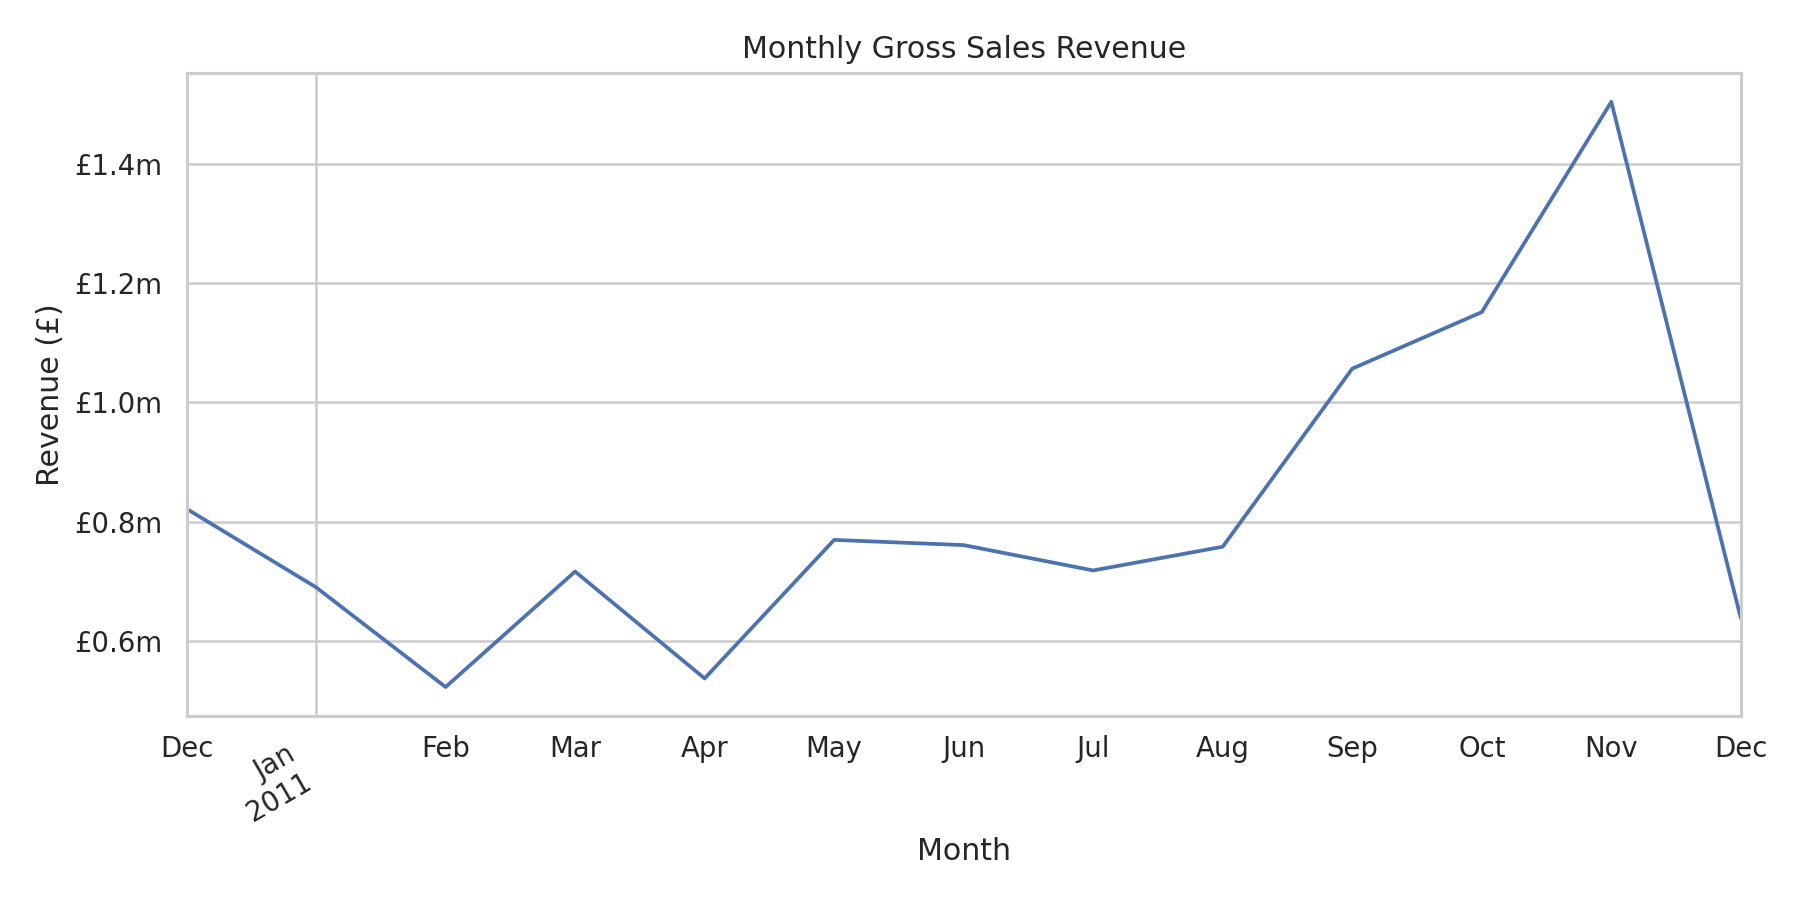

02_top_countries_bar.png


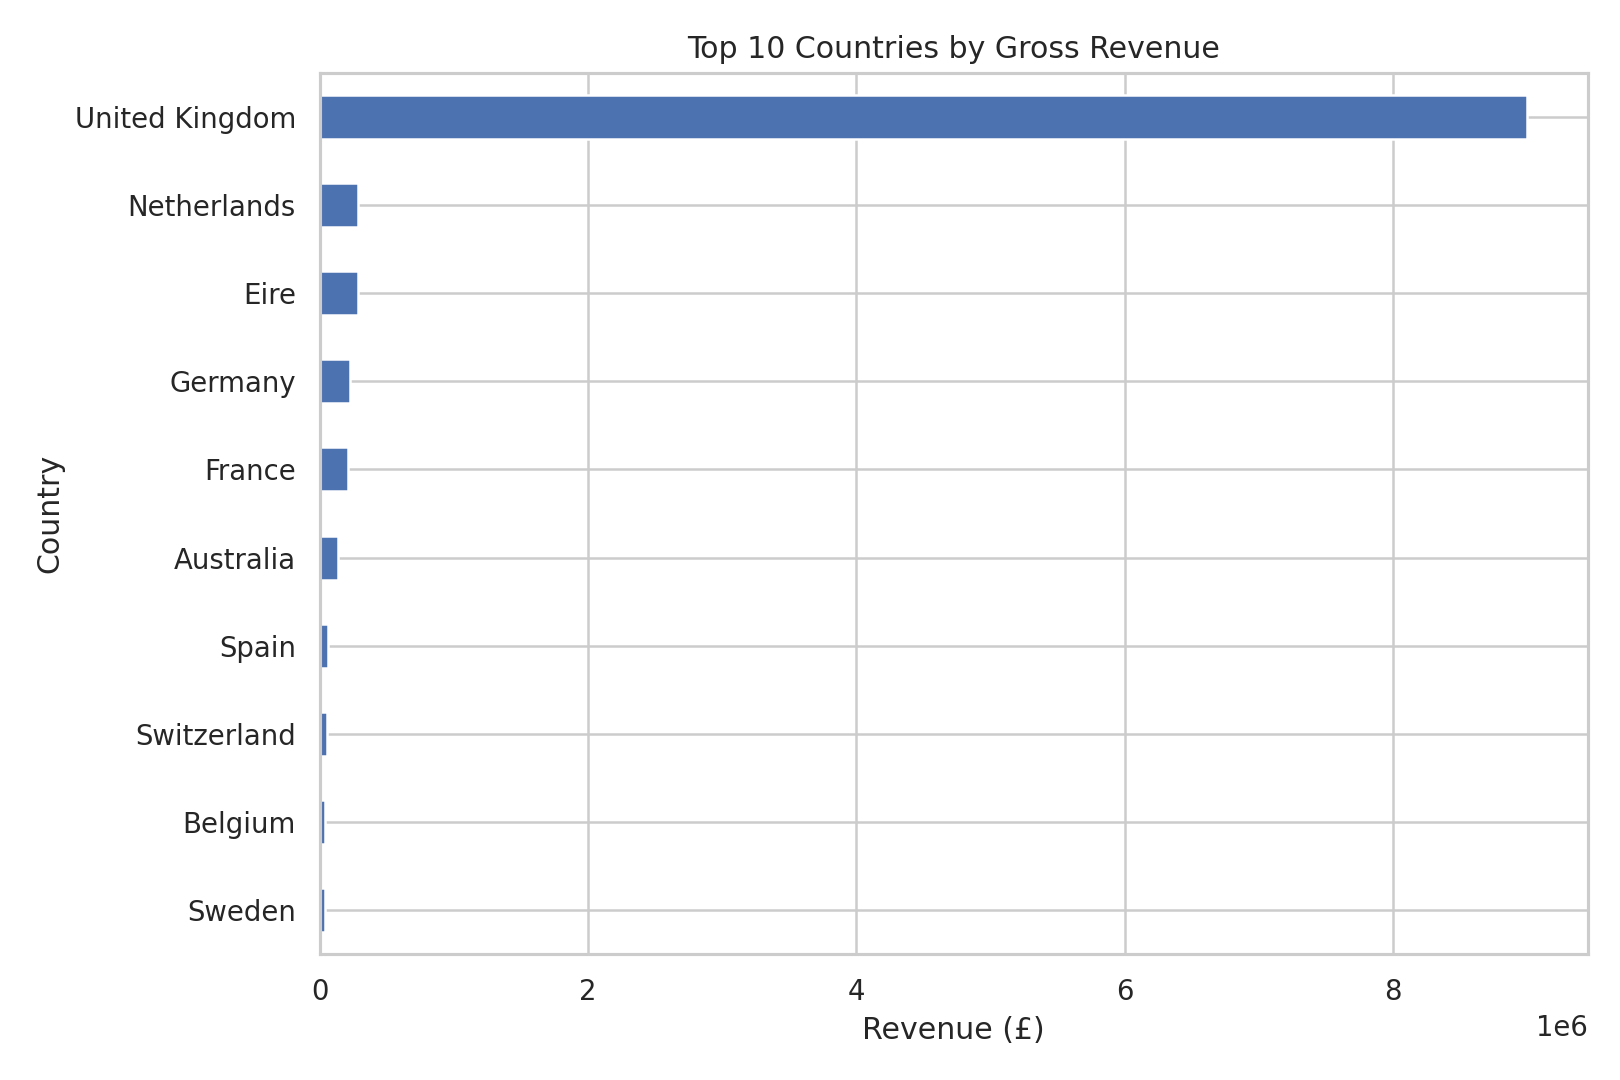

03_revenue_histogram.png


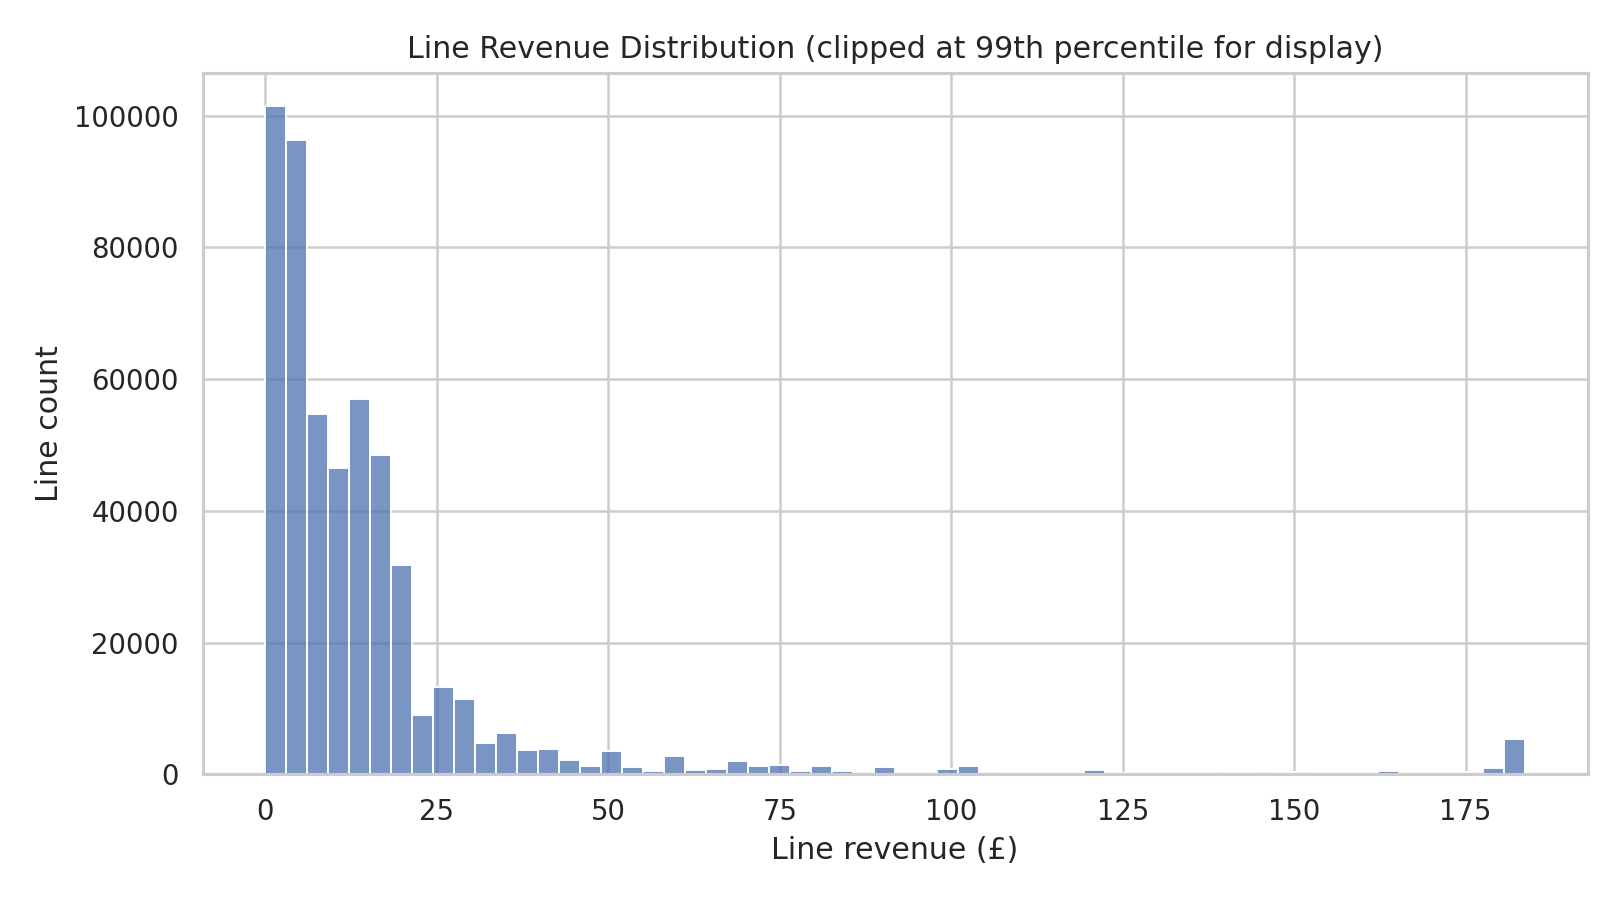

04_revenue_boxplot.png


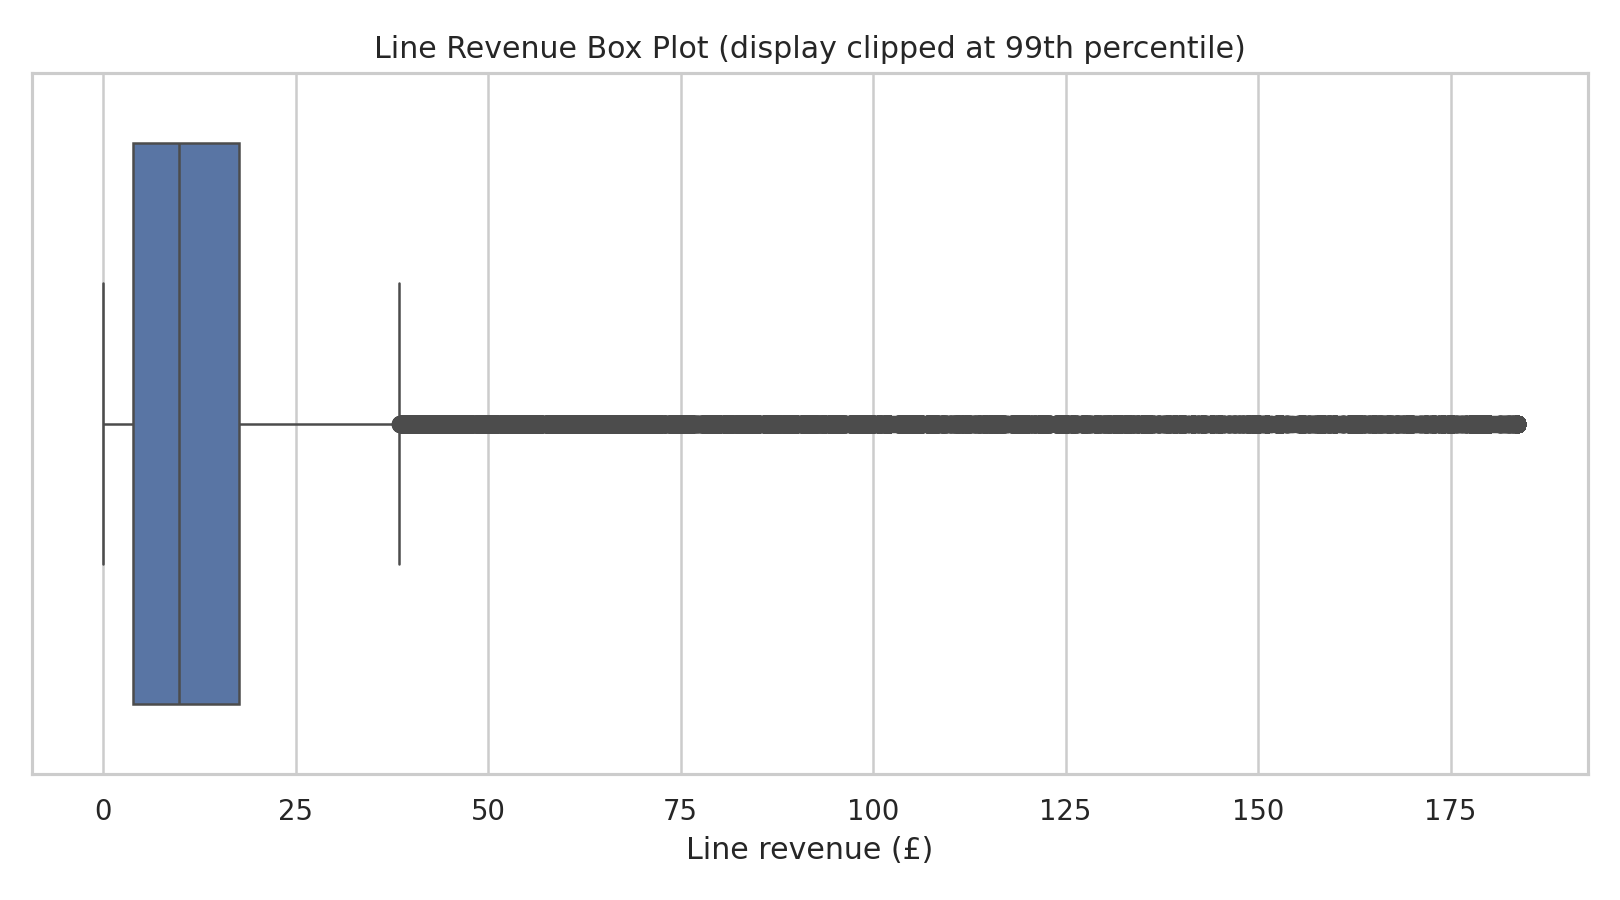

05_quantity_price_scatter.png


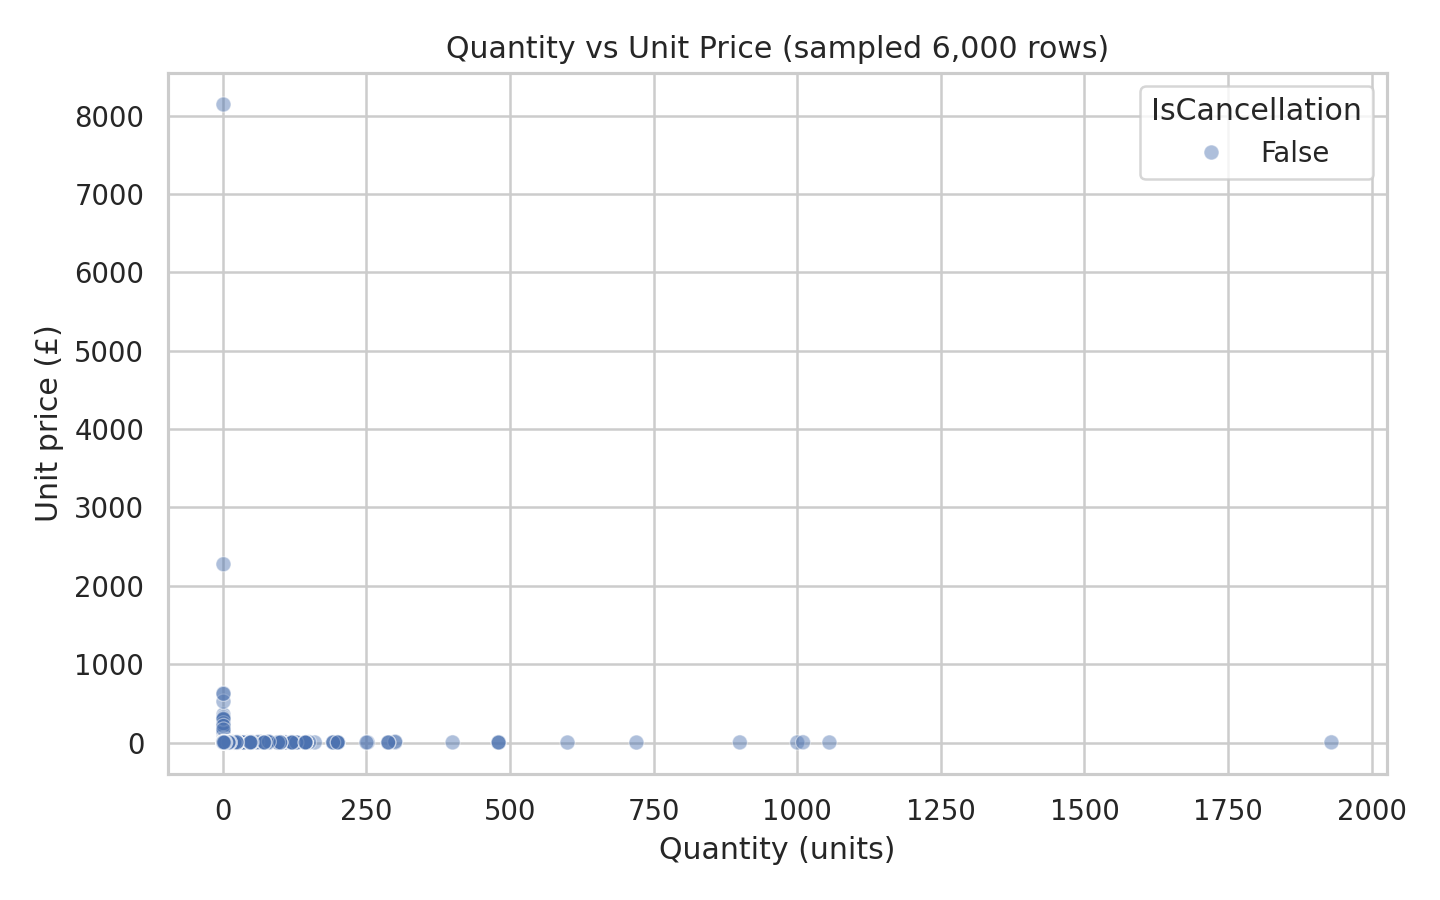

06_forecast_test.png


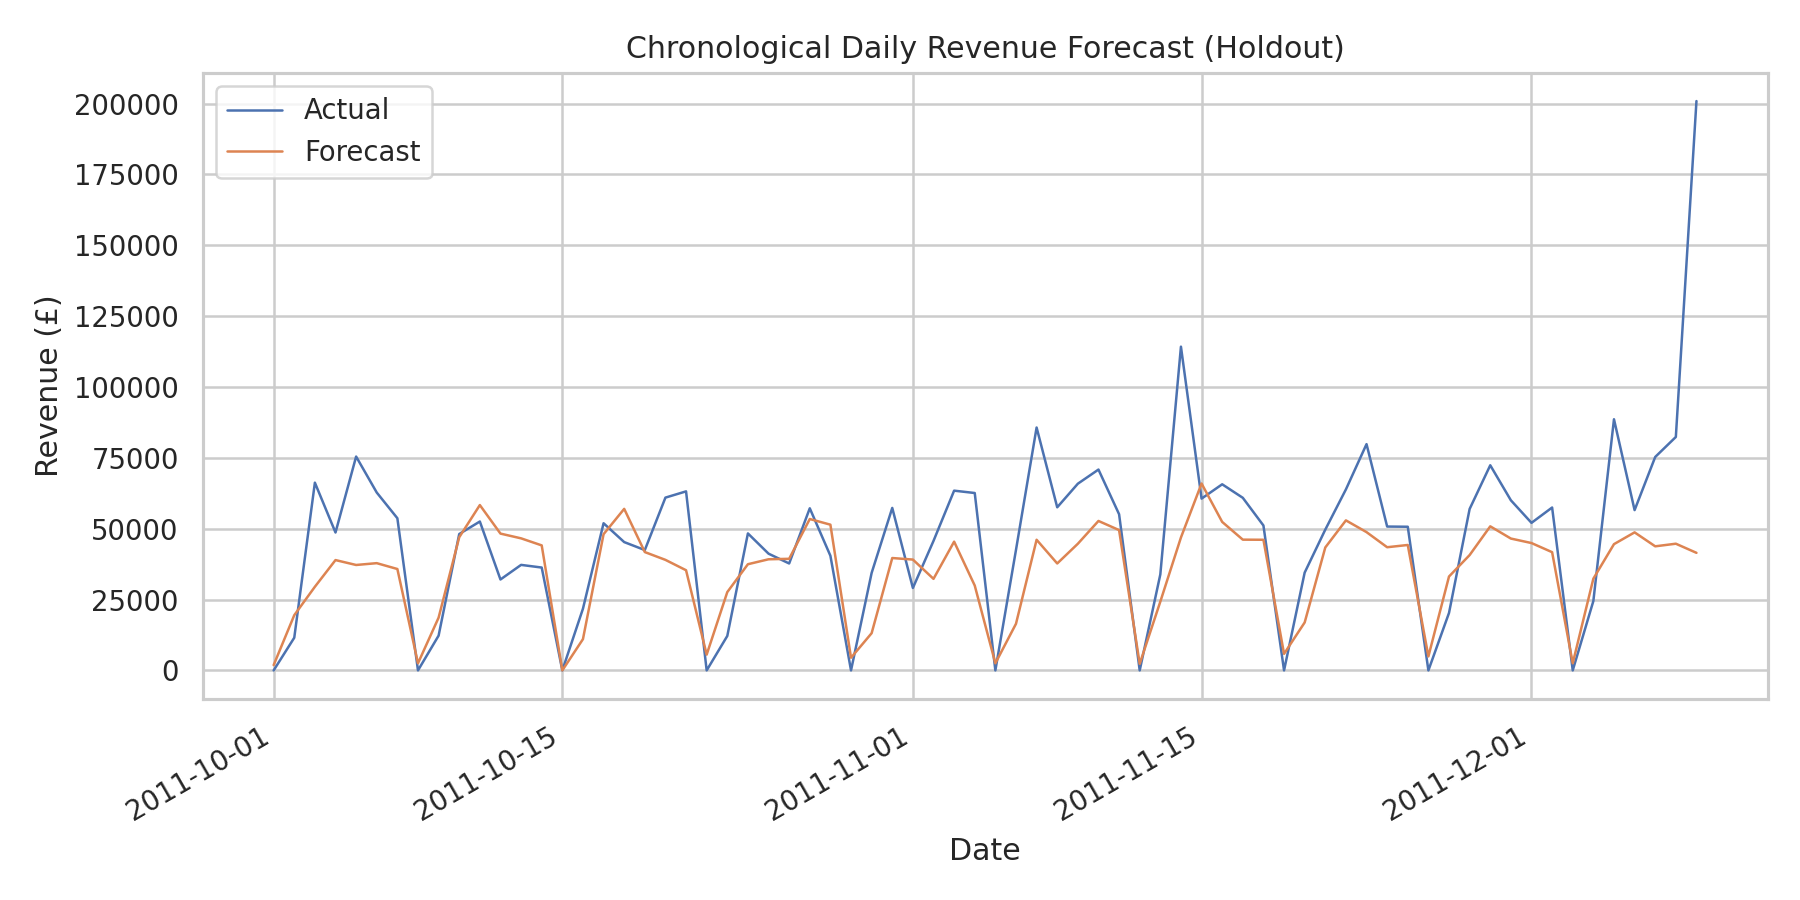

07_country_revenue_donut.png


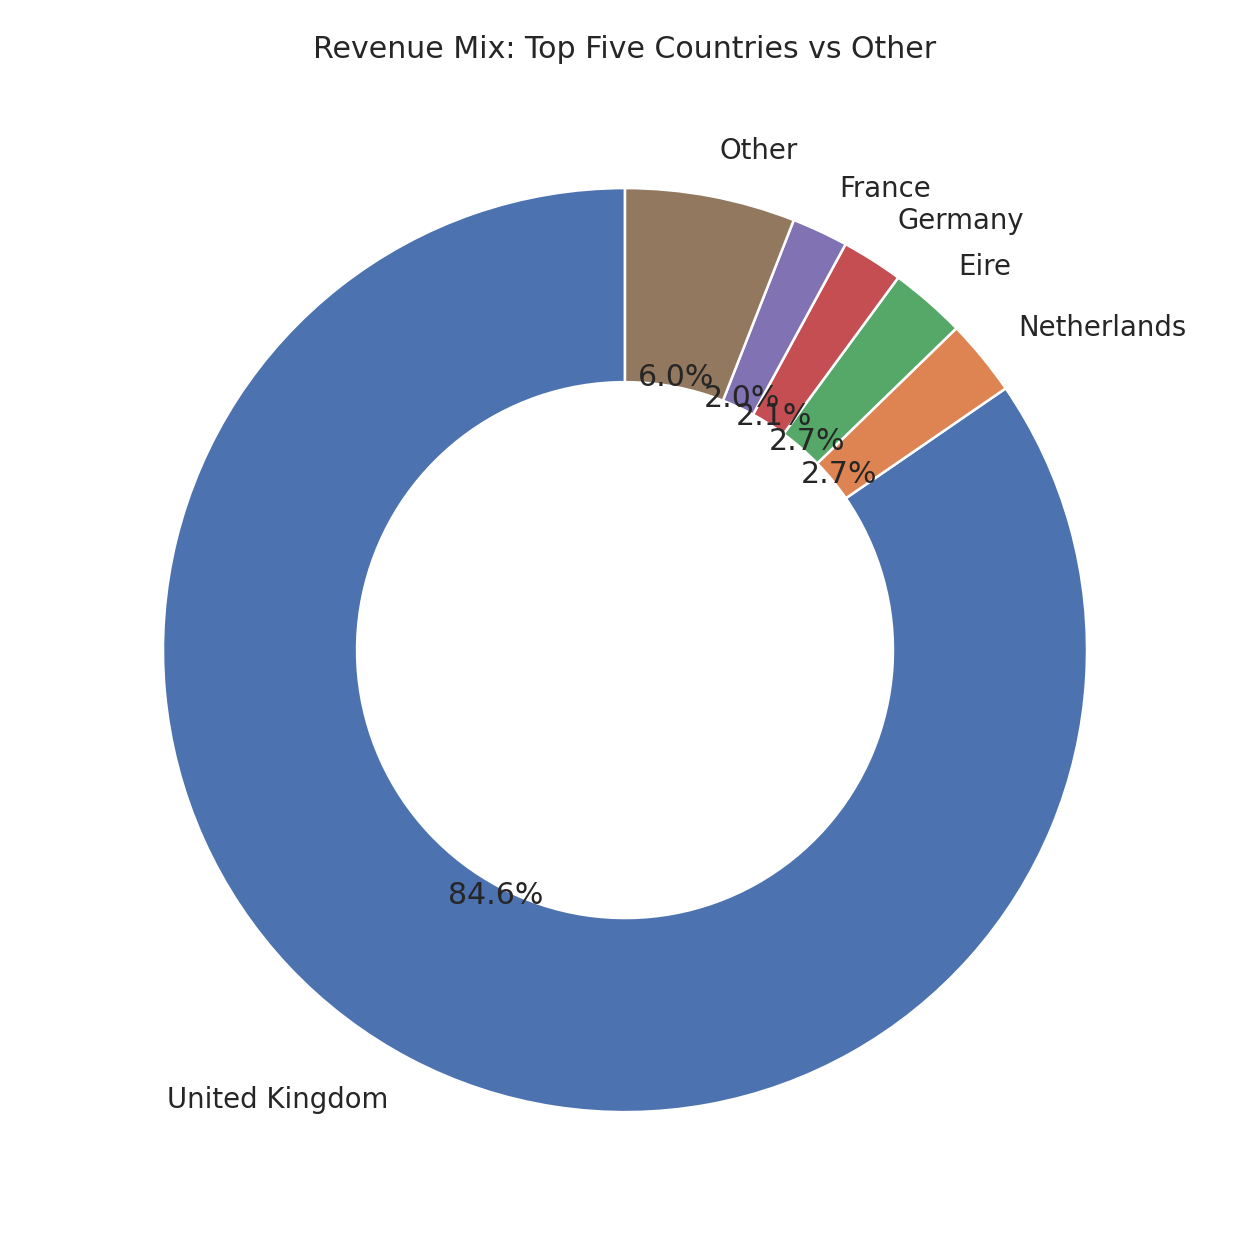

08_correlation_heatmap.png


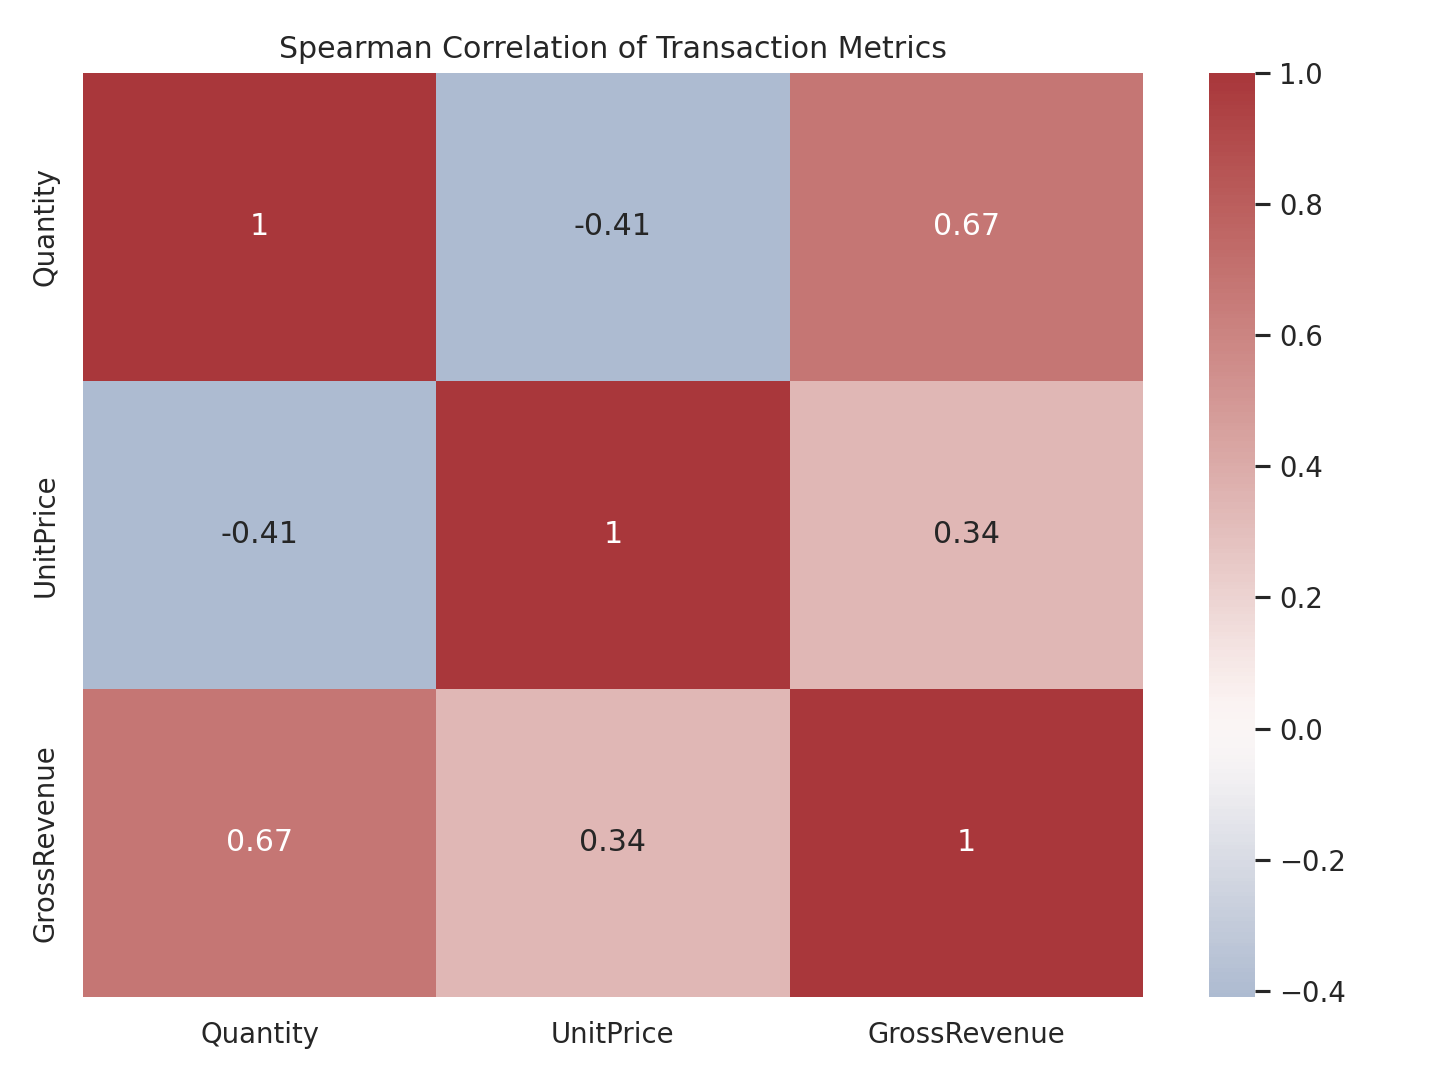

09_country_countplot.png


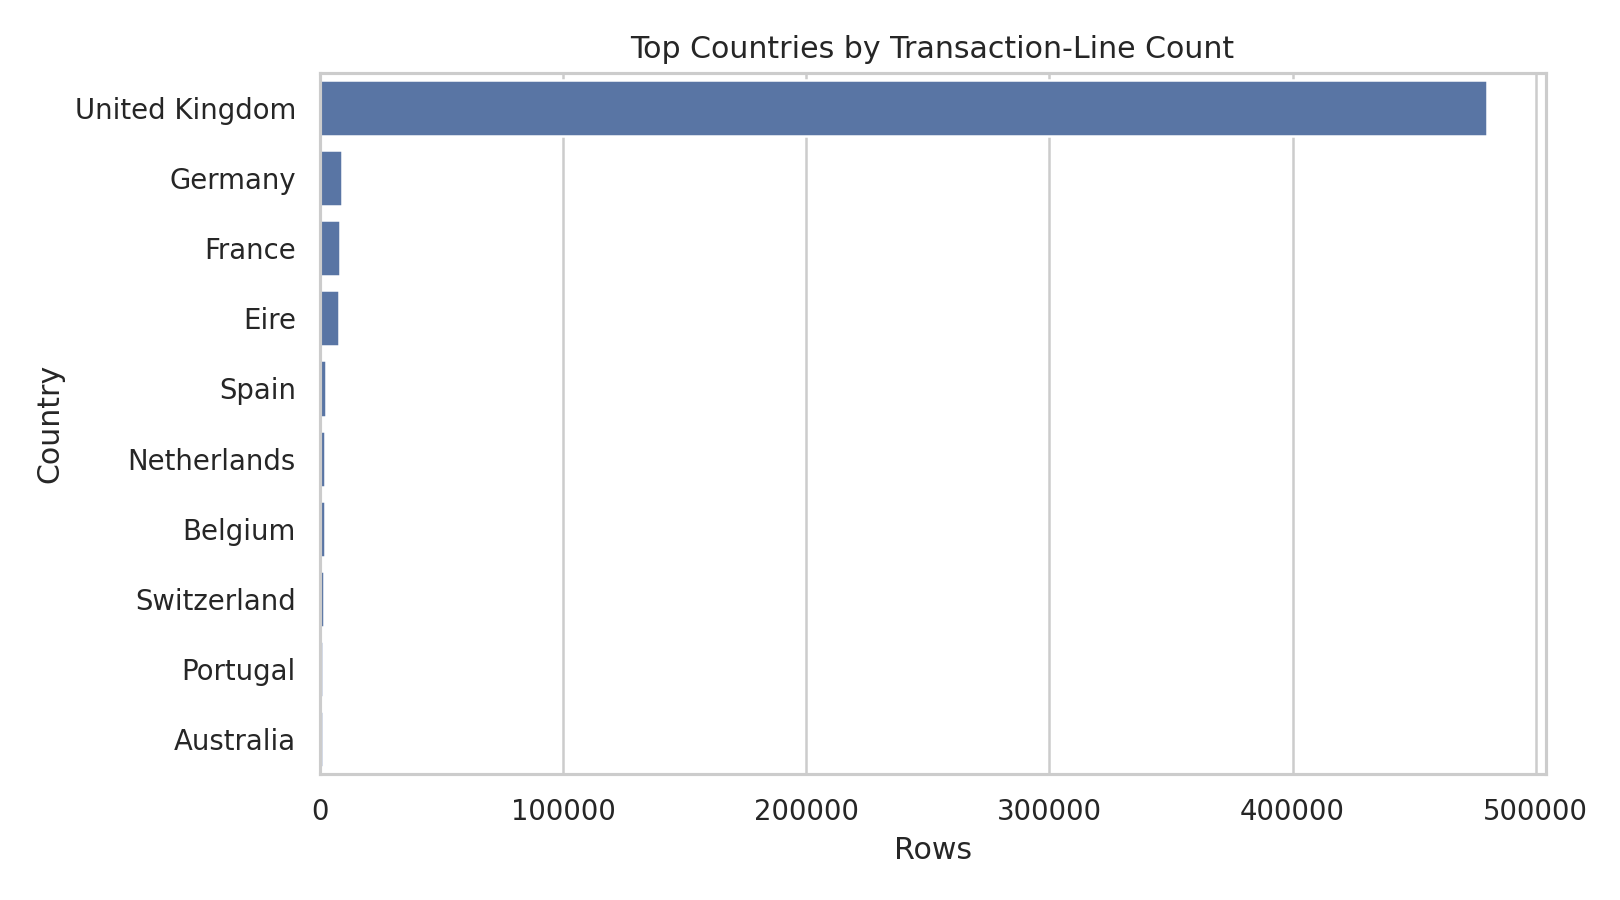

10_country_violin.png


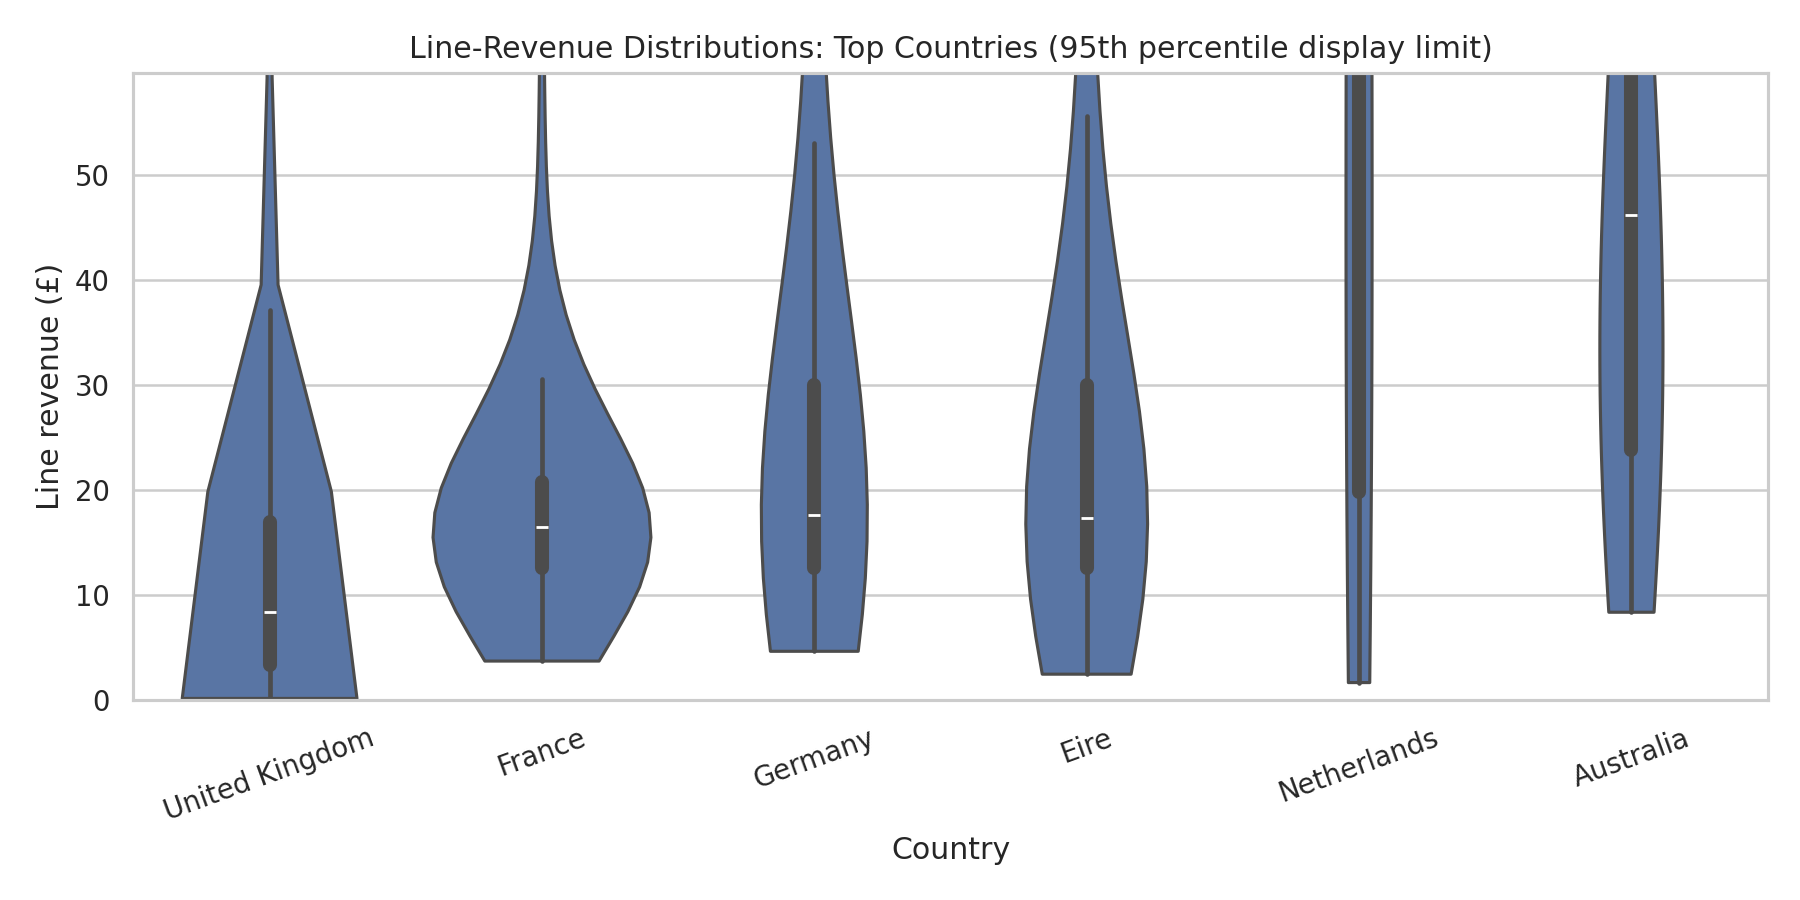

11_pairplot.png


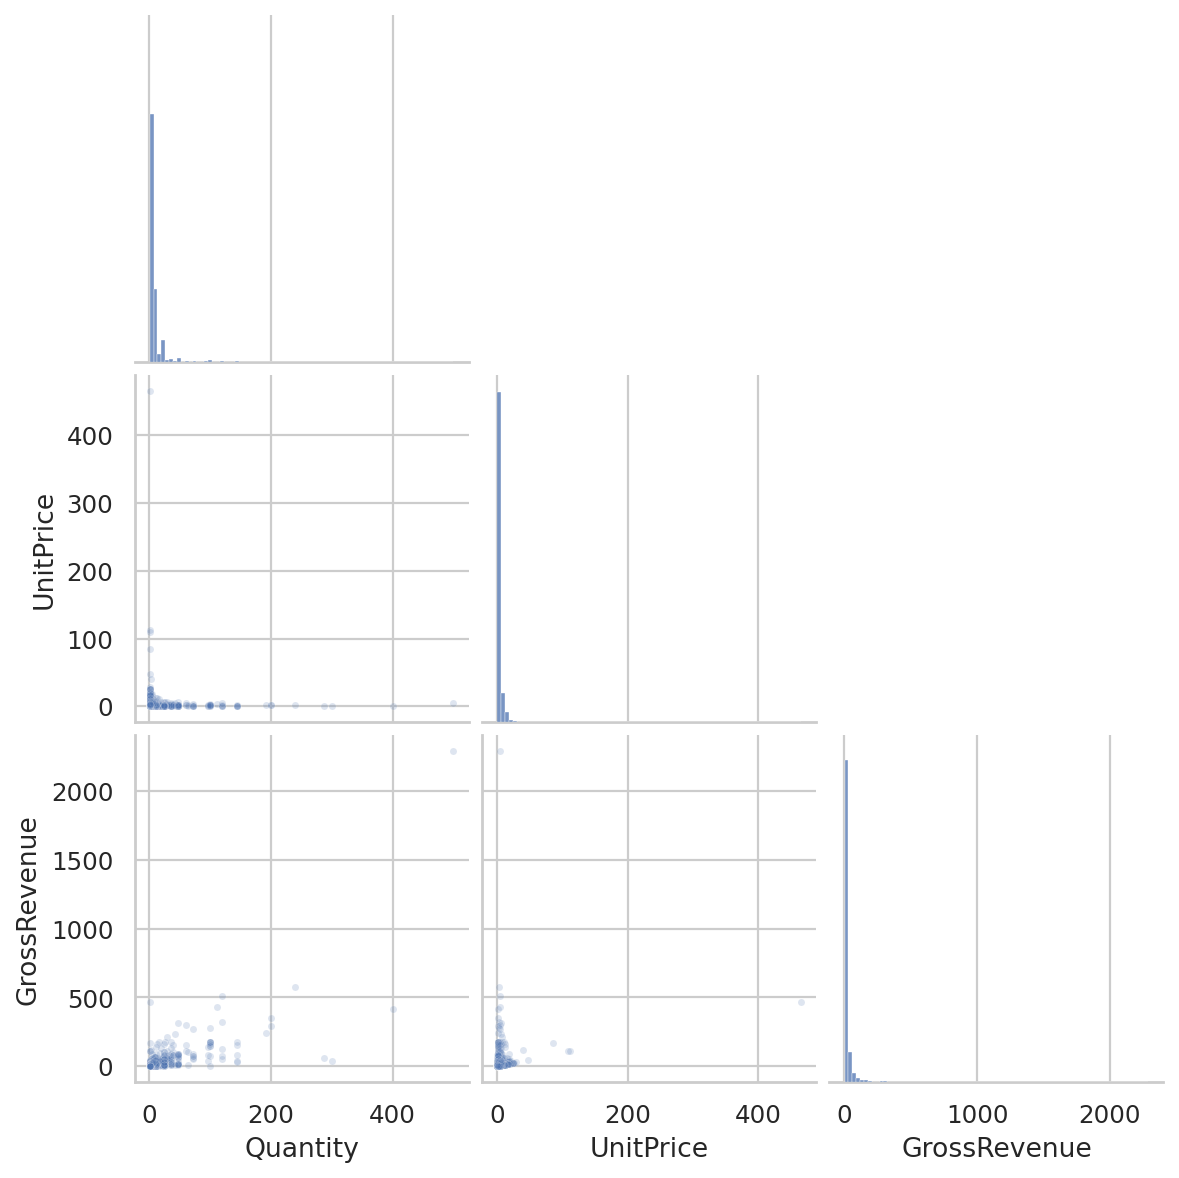

12_kpi_dashboard.png


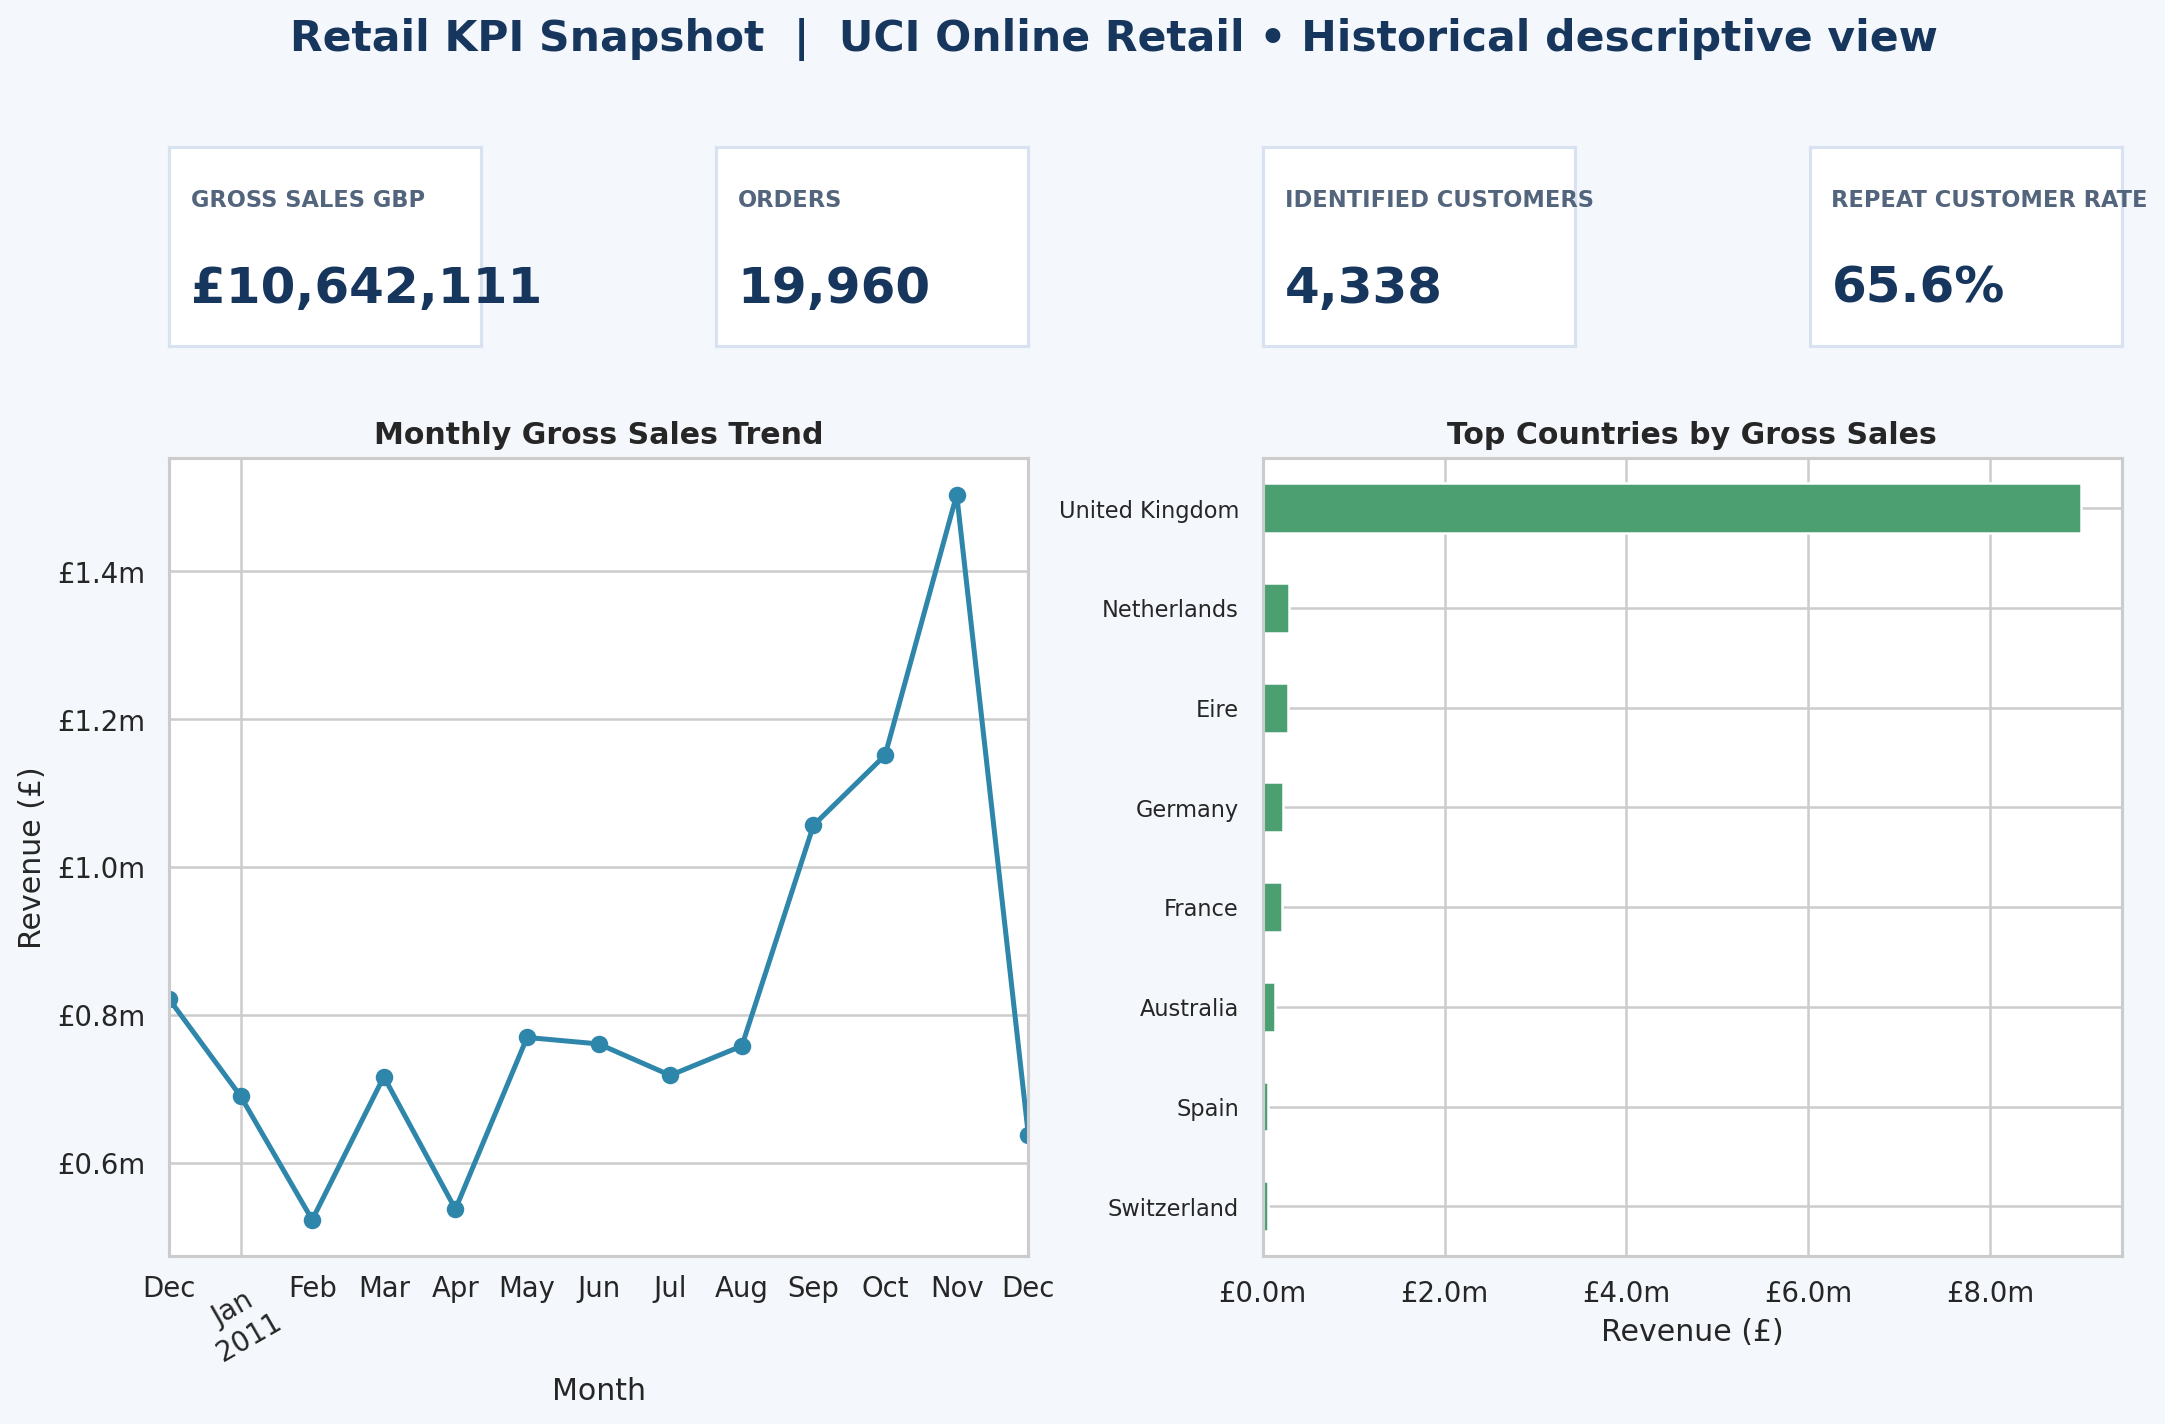

13_revenue_trend.png


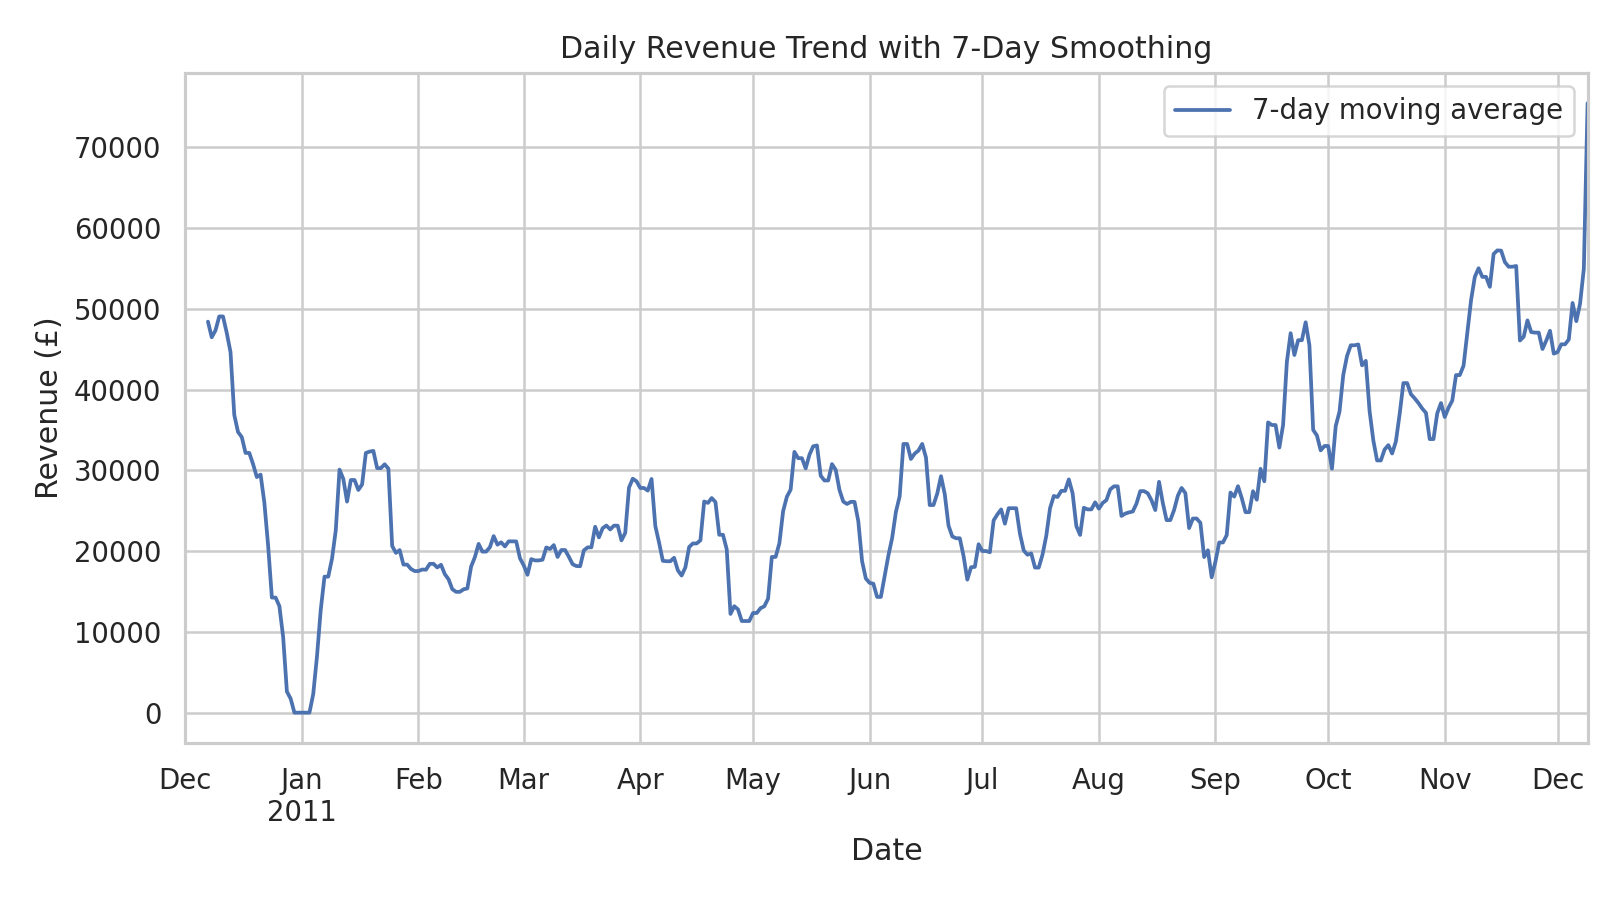

14_customer_revenue_hist.png


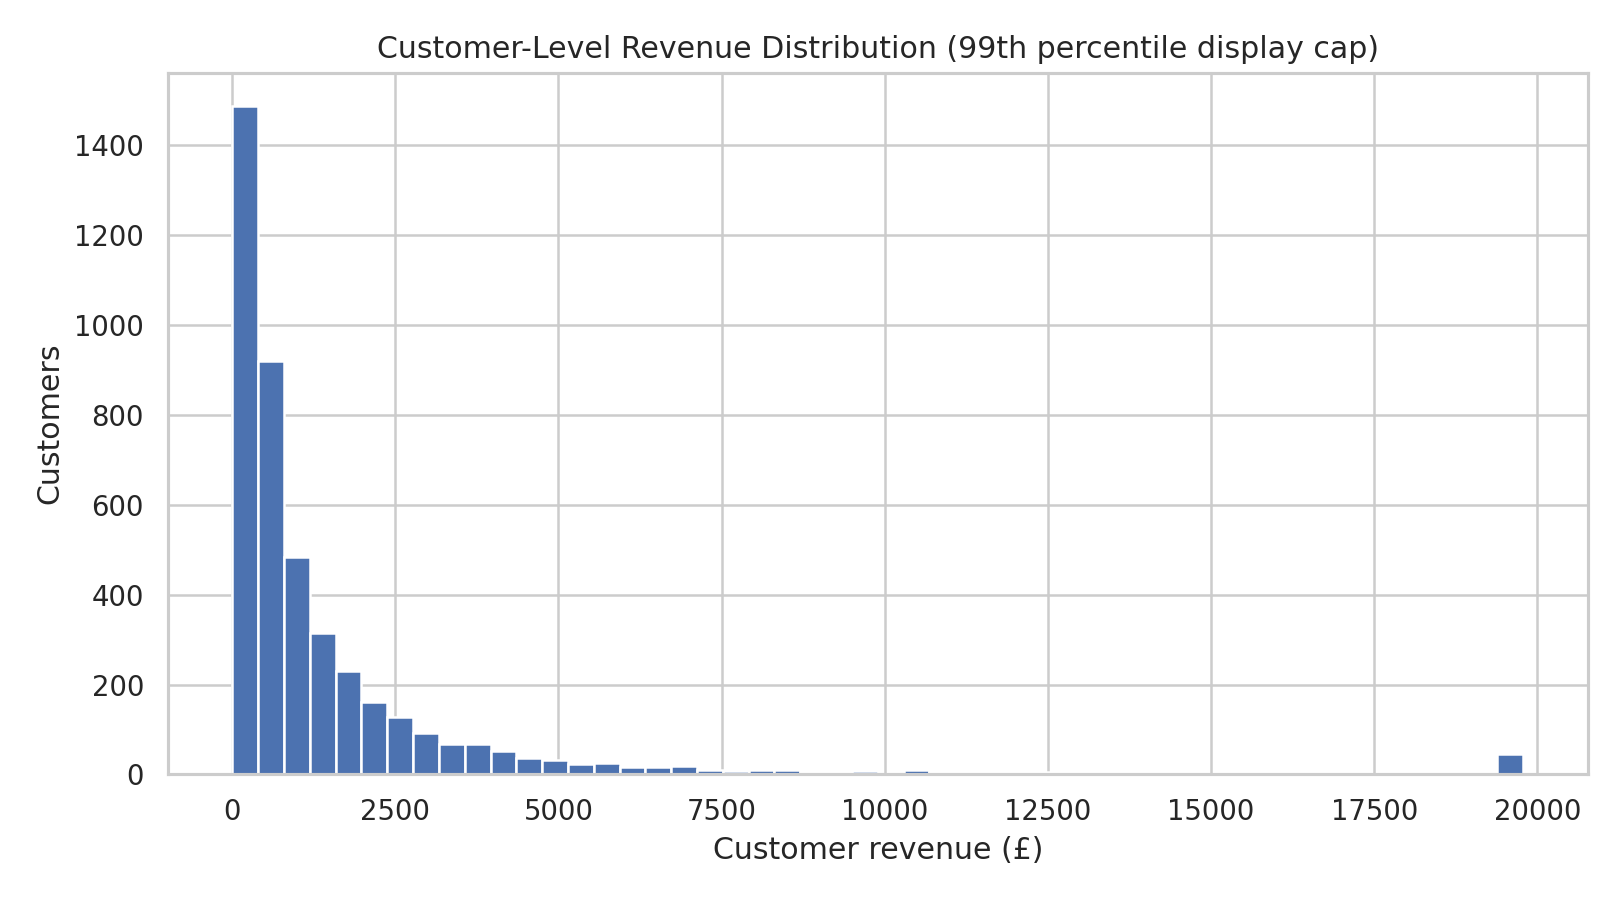

15_top_products.png


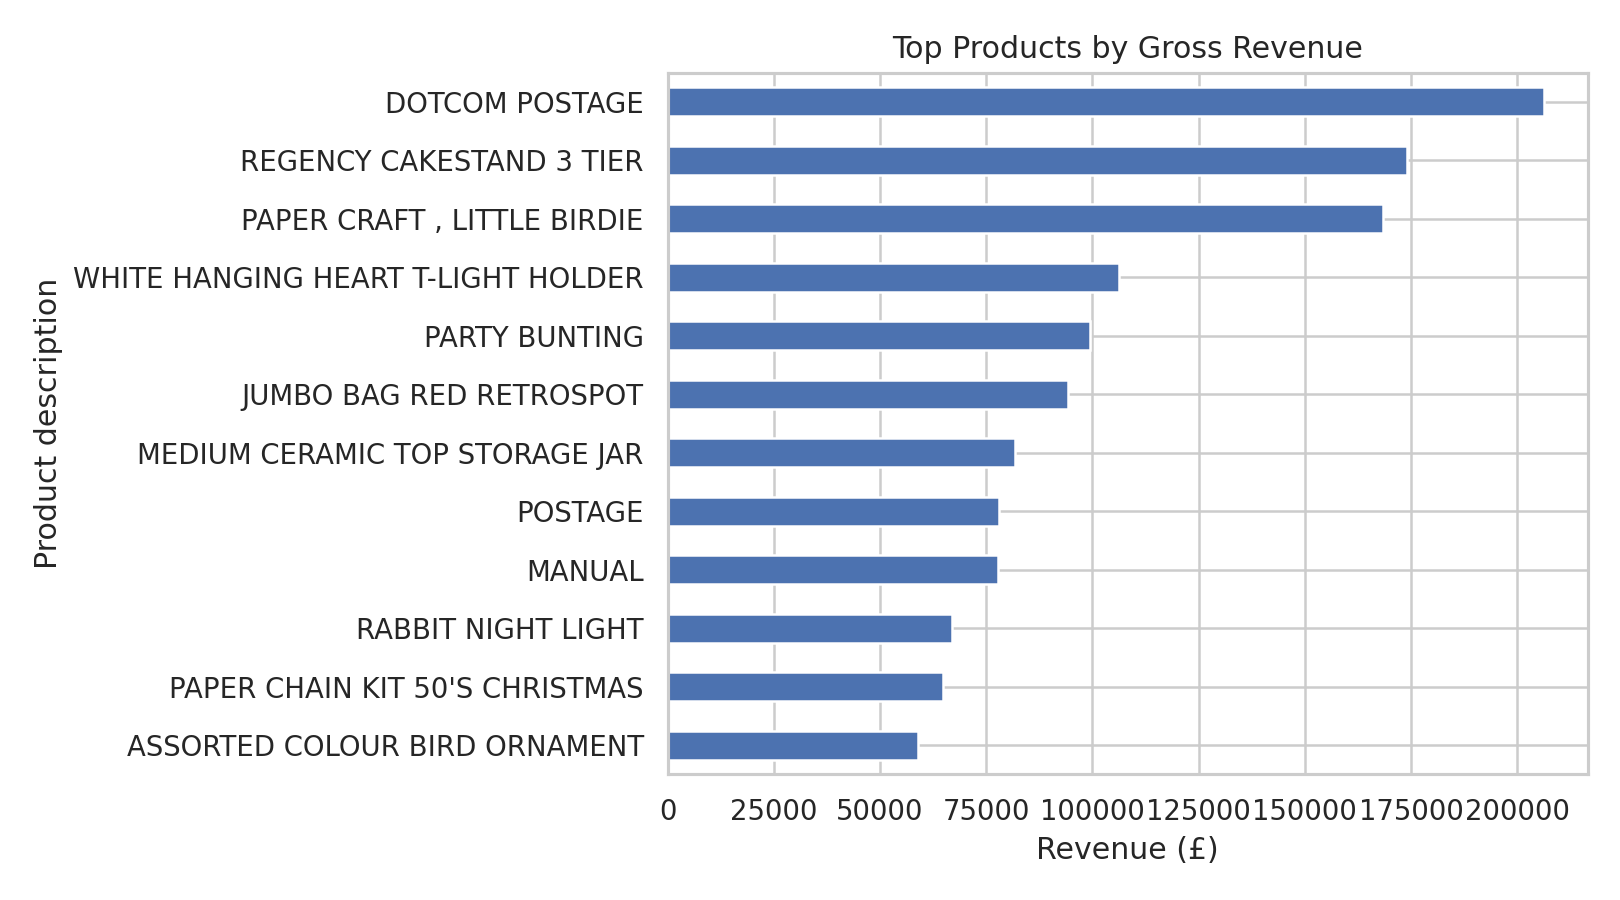

16_customer_orders_box.png


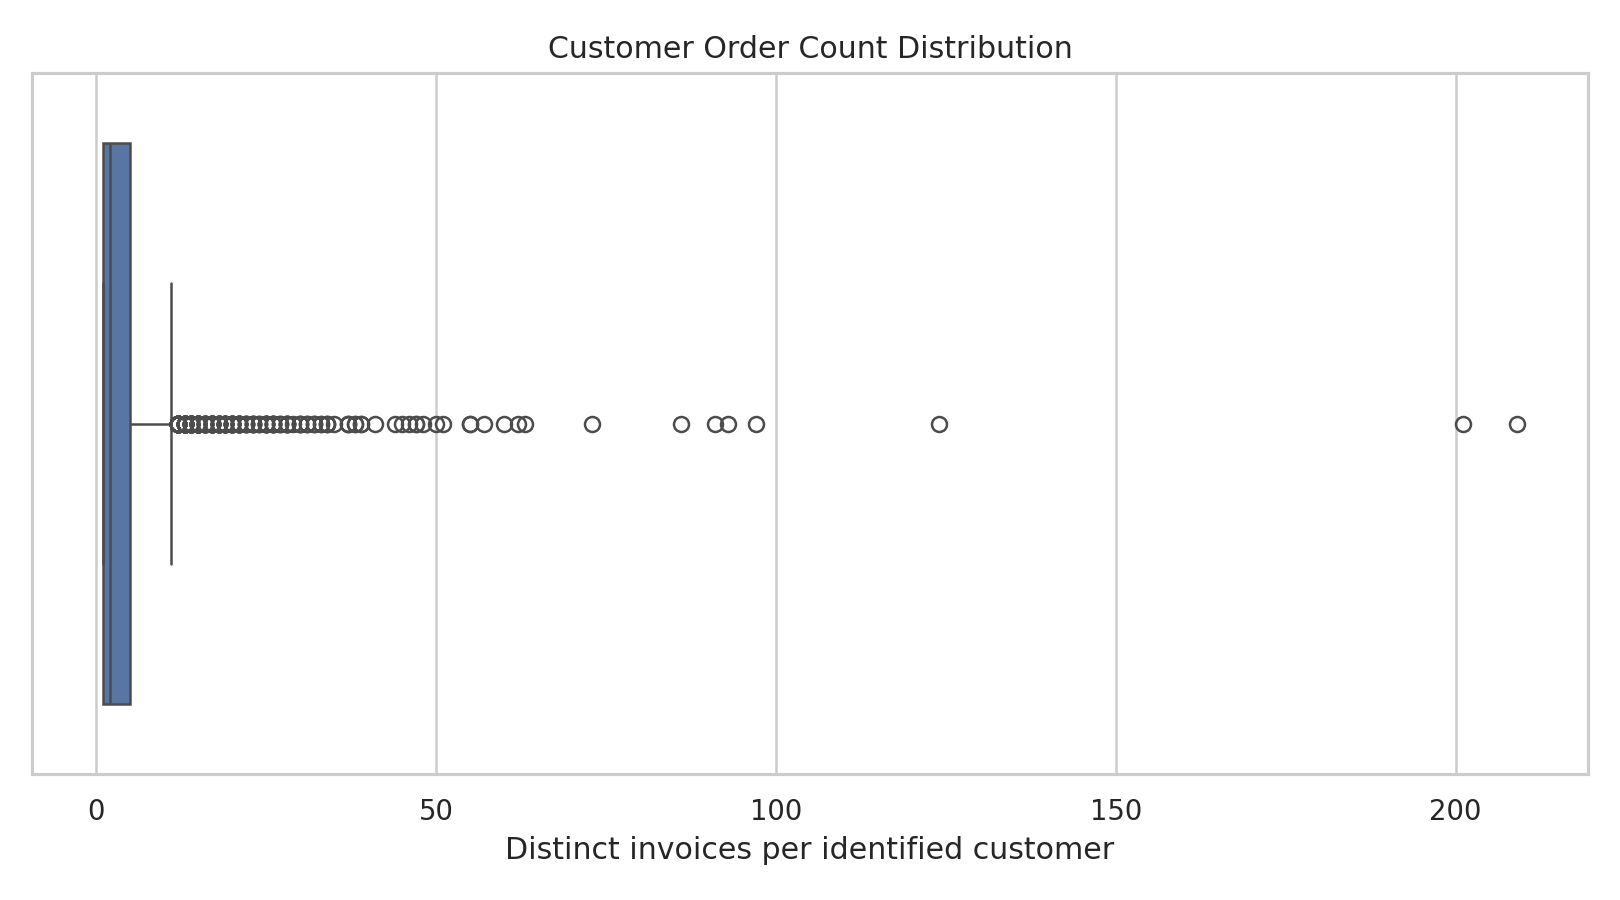

In [8]:
from IPython.display import display, Image
for f in sorted((ROOT/"visualizations").glob("*.png")):
    print(f.name); display(Image(filename=str(f),width=720))

## 8. Power BI Dashboard
Dashboard plan: KPI cards for gross sales, orders, units, identified customers, and repeat-customer share; monthly sales trend; top country/product bars; map only if supported by data category; slicers for date, country and product; drill-through to invoice/customer. Power Query steps and DAX are in `08_PowerBI/`. A static preview is included. A native `.pbix` file cannot be generated/validated here because Power BI Desktop is not available in this environment.

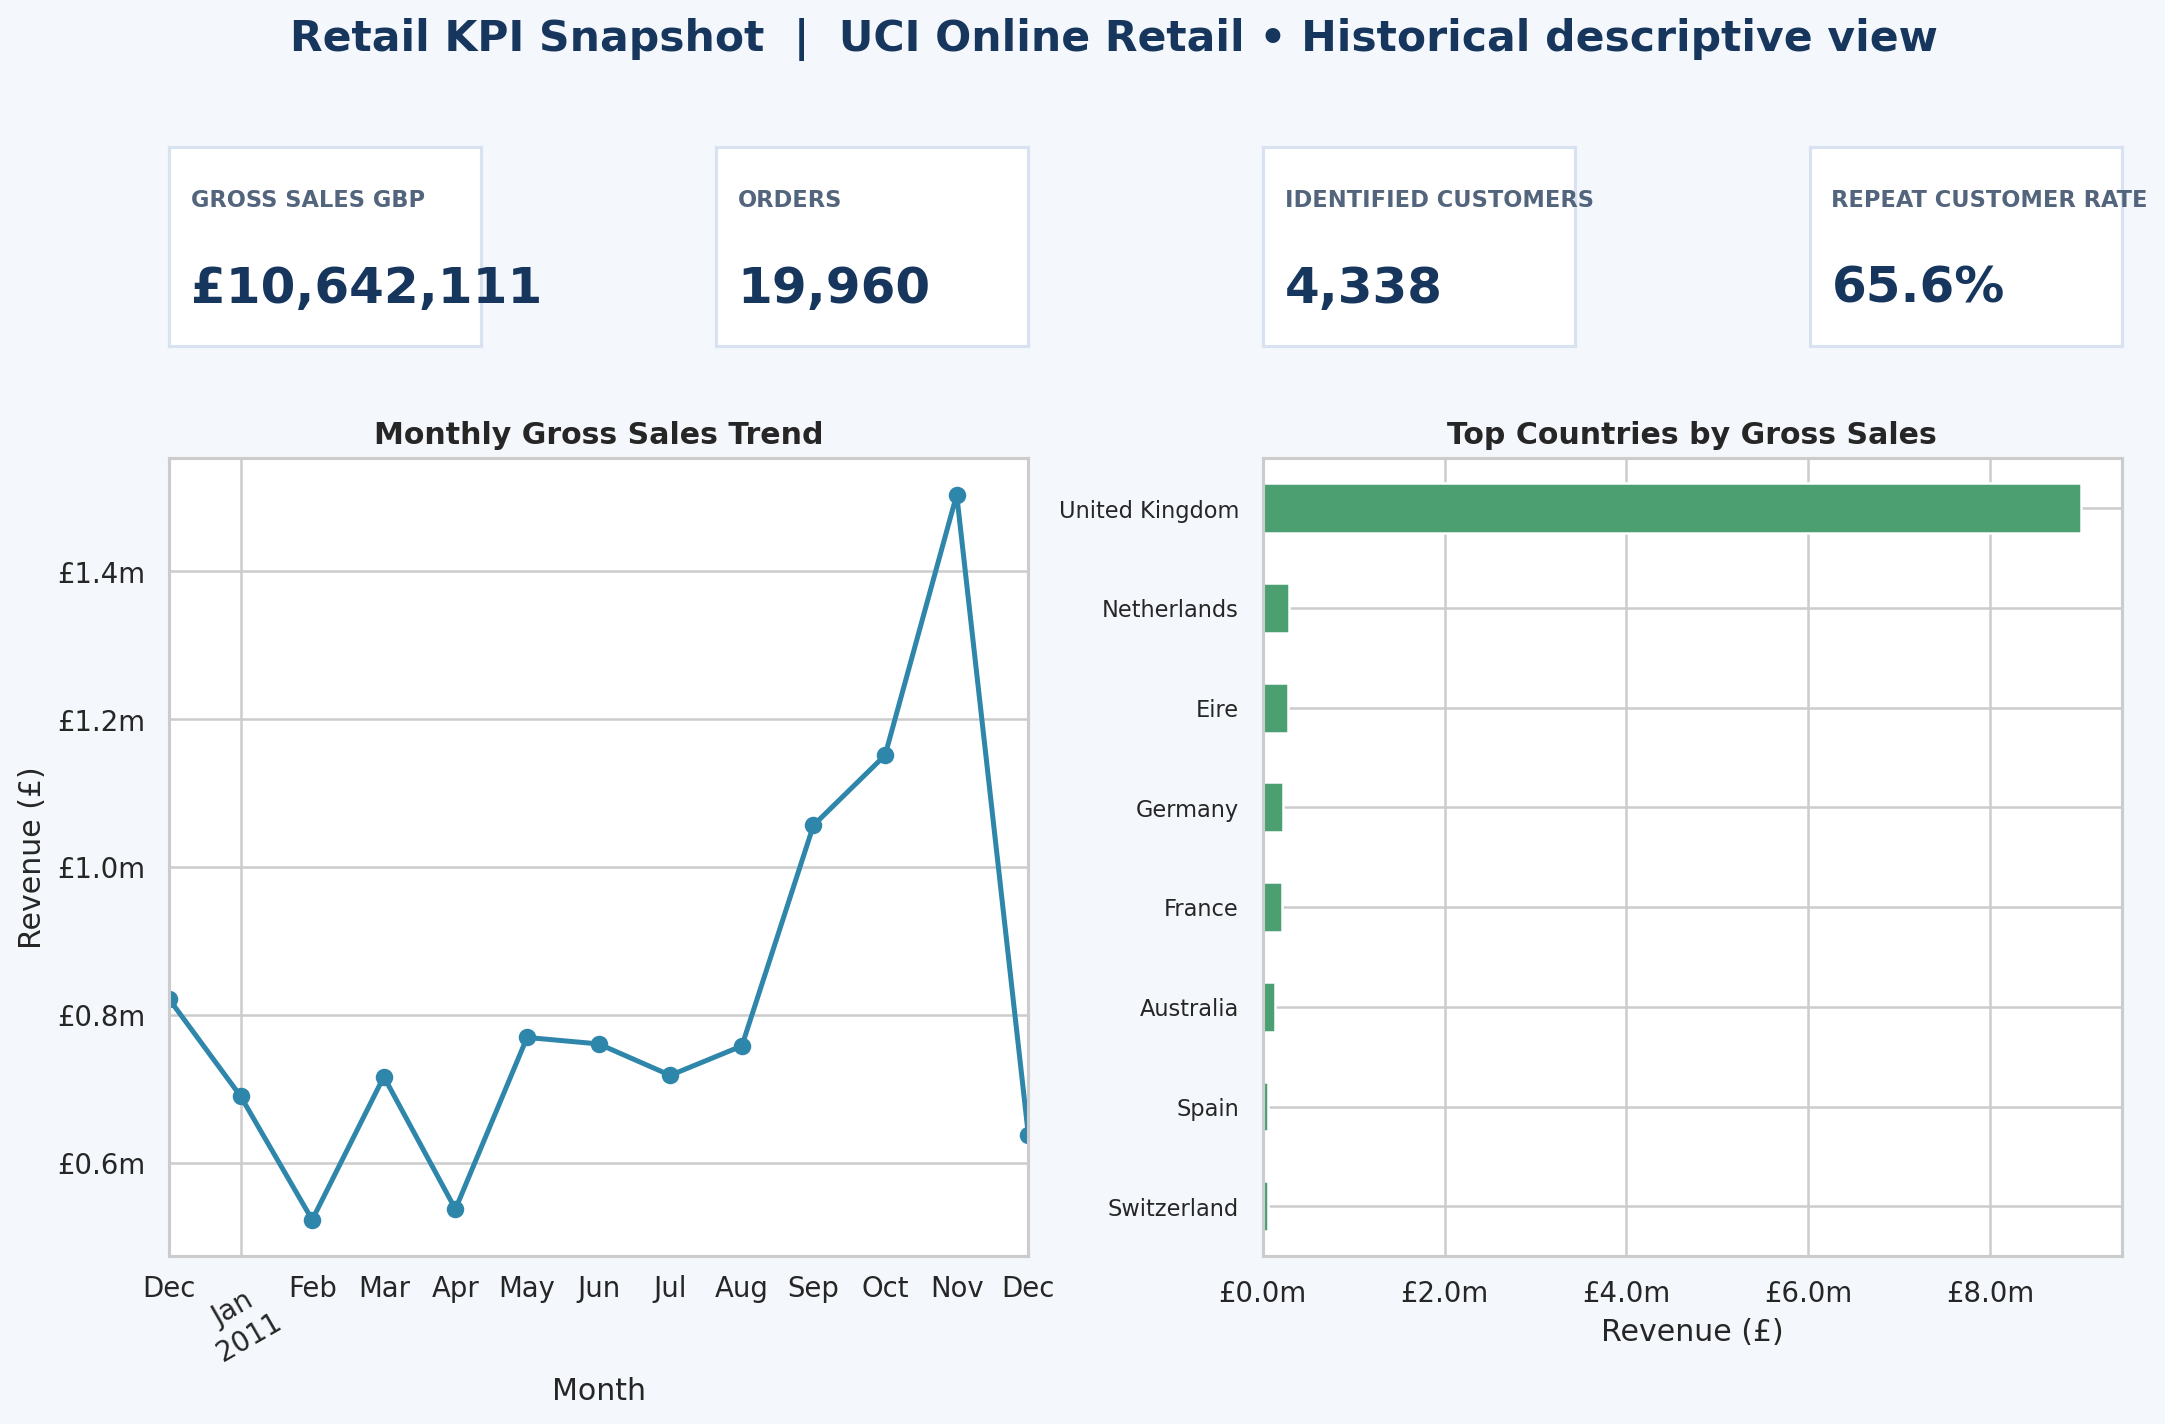

-- Import datasets/processed/online_retail_clean.csv as table Retail.
-- Build relationships/slicers using Date (created in Power Query), Country, and Description.
Gross Sales GBP = CALCULATE(SUM(Retail[LineRevenue]), Retail[IsCancellation] = FALSE(), Retail[Quantity] > 0, Retail[UnitPrice] > 0)
Order Count = CALCULATE(DISTINCTCOUNT(Retail[InvoiceNo]), Retail[IsCancellation] = FALSE(), Retail[Quantity] > 0)
Units Sold = CALCULATE(SUM(Retail[Quantity]), Retail[IsCancellation] = FALSE(), Retail[Quantity] > 0)
Identified Customers = CALCULATE(DISTINCTCOUNT(Retail[CustomerID]), NOT(ISBLANK(Retail[CustomerID])), Retail[IsCancellation] = FALSE())
Repeat Customers = COUNTROWS(FILTER(VALUES(Retail[CustomerID]), NOT(ISBLANK(Retail[CustomerID])) && CALCULATE(DISTINCTCOUNT(Retail[InvoiceNo]), Retail[IsCancellation] = FALSE(), Retail[Quantity] > 0) > 1))
Repeat Customer Rate = DIVIDE([Repeat Customers], [Identified Customers])
Average Order Value = DIVIDE([Gross Sales GBP], [Order Count])
Sales pe

In [9]:
from IPython.display import display, Image
display(Image(filename=str(ROOT/"visualizations/12_kpi_dashboard.png"),width=800))
print((ROOT/"08_PowerBI/DAX_measures.dax").read_text())

## 9. Machine Learning Fundamentals
Daily revenue regression uses time-ordered holdout dates. Lag/rolling predictors are computed from previous days only. Weekly-naive baseline predicts revenue from seven days earlier. Compare MAE/RMSE/R²; the ML model does not outperform this baseline here, so do not deploy it as a forecast. This is a learning exercise, not a production model.

In [10]:
m=results["forecast_metrics"]
print(json.dumps(m,indent=2))
assert m["test_start"]>m["train_end"]
assert m["MAE_GBP"]>=0 and m["weekly_naive_MAE_GBP"]>=0
print("Model-vs-baseline MAE delta (£):",round(m["MAE_GBP"]-m["weekly_naive_MAE_GBP"],2))

{
  "MAE_GBP": 16429.54,
  "RMSE_GBP": 26809.95,
  "R2": 0.2778,
  "weekly_naive_MAE_GBP": 14165.99,
  "baseline_RMSE_GBP": 24334.25,
  "train_end": "2011-09-30",
  "test_start": "2011-10-01"
}
Model-vs-baseline MAE delta (£): 2263.55


## 10. Tool Comparison and Conclusion
Use Excel for small, auditable ad hoc tables; Python for repeatable transformations and modeling. NumPy is efficient for numeric arrays; Pandas adds labeled relational data tools. SQL is best for persistent, set-based filtering/aggregation near a database; Python coordinates analysis and modeling. Power BI provides governed interactive reporting; Matplotlib/Seaborn provide reproducible static figures. Jupyter is a local reproducible artifact; Colab eases cloud setup but requires data governance review. Scikit-learn standardizes model pipelines/validation; direct SciPy/statistical calculations are better for explicit inferential tests.

**Responsible interpretation:** UCI data are historical and observational. No causal impact, margin, current trading behavior, or future forecast reliability is established. Dataset attribution is required under CC BY 4.0.